# Self-Gating Reconstruction Pipeline Example


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from utils.bin import read_path,extract_nav_tr,process_nav_signal,extract_nav_tr_cv


## 1. Pulse Sequence Overview

The custom pulse sequences are modified from standard commercial Siemens sequences, including GRE (`a_gre`), bSSFP (`trufi`), and CV (Cardiovascular Cine).

As described in the paper:
- An ultra-short ADC readout is inserted prior to the slice-refocusing gradient to acquire navigator signals.
- The Siemens Measurement Data Header (MDH) system is used to tag these navigation ADCs with the `PHASCOR` flag for identification.
- The `ONLINE` flag is cleared for these navigator readouts so they do not interfere with standard online image reconstruction on the host system.

Each navigation ADC readout contains 10 sample points (using Siemens' default 2x oversampling ratio). The magnitude of the readout is extracted for downstream self-gating processing.


In [2]:
data_dir=Path("../CMRdata/A02_A049_0/A02_A049_0_SelfGated_raw/meas_MID00146_FID00205_CV_SG_BreathHold_slc_4.dat")   
twix=read_path(data_dir)
nav_signal,TR,beginning_timestamp=extract_nav_tr_cv(twix)
total_num_acqs=nav_signal.shape[1]


Software version: VD/VE (!?)

Scan  0


100%|██████████| 148M/148M [00:00<00:00, 181MB/s] 



number of separate scans (multi-raid): 1
MDB total number is:  5082
Segment counts: Counter({11: 178, 12: 176, 13: 175, 8: 174, 10: 174, 6: 172, 7: 172, 9: 172, 1: 171, 0: 170, 2: 170, 3: 170, 4: 170, 5: 170, 14: 1})
Scanning MDB headers sequentially...


100%|██████████| 5082/5082 [00:02<00:00, 1747.38it/s]

Time Stamp starts at:  17888663
before mean shape  (16, 2414, 10)
after mean shape  (16, 2414)
Detected 13 segment boundaries
Number of PE lines per segment: 8
Boundary indices: [ 169  340  510  680  850 1020 1192 1364 1538 1710 1884 2062 2238]
Segment Repetition Time (TR): 0.04656 s
--- Applying Stitching (De-Stepping) ---


### Signal Preprocessing & Filtering

- **Steady-State Line Discard (`discard_num`)**: Phase-encoding lines acquired before reaching steady state can be discarded. Unlike Siemens CV (which includes dedicated dummy scan modules for ECG/external gating), standard commercial Siemens sequences may lack dummy scans. In CV mode, all acquired lines can typically be retained. We used CV in the cine imaging(This experiment).
- **Low-Frequency Drift**: During breath-hold acquisitions, navigator signals across certain coil channels may exhibit slow linear or monotonic trends (e.g., due to ventilator air delivery in animal studies or subtle thoracic movement during human breath-holds).
- **Filtering Strategy**: Rather than applying explicit linear detrending, the signal is padded and bandpass/high-pass filtered. These slow baseline drifts reside below 0.1 Hz and are effectively removed by the filter.


There are some spikes in the raw signal, because during that experiment, the contact pin of the pig coil had some issues so there are electrical spikes, yet, the algorithms are very robust to these spikes and still produce accurate result.

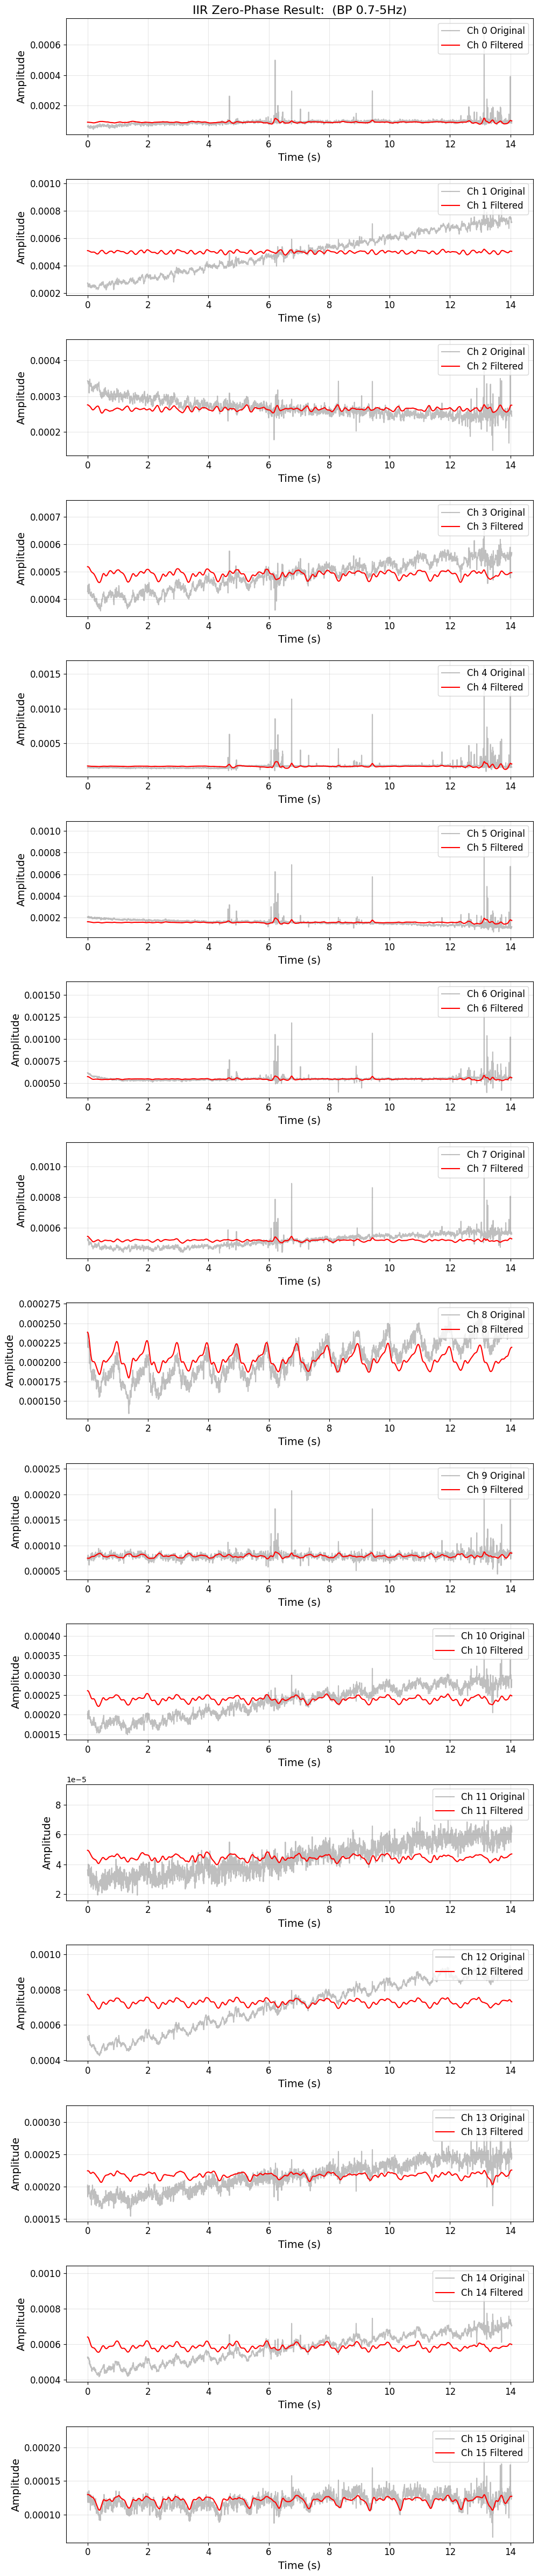

In [3]:
discard_num=0   
nav_signal_tensor=process_nav_signal(nav_signal[:,discard_num:],fs=1/(TR),free_breath=False,plot=True)

### Dimensionality Reduction & Gating Optimization

- **Model Training & Convergence**: Training typically converges within 10 to 30 epochs (~1 second execution time). Using a second-order optimizer with Wolfe line-search conditions ensures rapid convergence.
- **Deterministic Inference**: Because the number of sample points (e.g., 2,414) vastly exceeds the model parameter count (380), inference yields highly reproducible gating points across runs.
- **Framework Comparison**: A JAX implementation is also available. While JAX offers faster execution after compilation, PyTorch is faster for single-pass notebook runs due to JAX's initial JIT compilation overhead.


Input data shape: torch.Size([2414, 16])
Model has 380 parameters
Starting AE Training... 🚀
Epoch [1/30], Total Loss: 0.26681131
Epoch [2/30], Total Loss: 0.02896231
Epoch [3/30], Total Loss: 0.00092257
Epoch [4/30], Total Loss: 0.00012261
Epoch [5/30], Total Loss: 0.00011157
Epoch [6/30], Total Loss: 0.00010952
Epoch [7/30], Total Loss: 0.00010931
Epoch [8/30], Total Loss: 0.00010819
Epoch [9/30], Total Loss: 0.00010442
Epoch [10/30], Total Loss: 0.00010126
Epoch [11/30], Total Loss: 0.00009304
Epoch [12/30], Total Loss: 0.00008937
Epoch [13/30], Total Loss: 0.00008793
Epoch [14/30], Total Loss: 0.00007696
Epoch [15/30], Total Loss: 0.00007086
Epoch [16/30], Total Loss: 0.00006987
Epoch [17/30], Total Loss: 0.00006809
Epoch [18/30], Total Loss: 0.00006767
Epoch [19/30], Total Loss: 0.00006693
Epoch [20/30], Total Loss: 0.00005941
Epoch [21/30], Total Loss: 0.00005485
Epoch [22/30], Total Loss: 0.00005251
Epoch [23/30], Total Loss: 0.00005217
Epoch [24/30], Total Loss: 0.00005212
Epoch

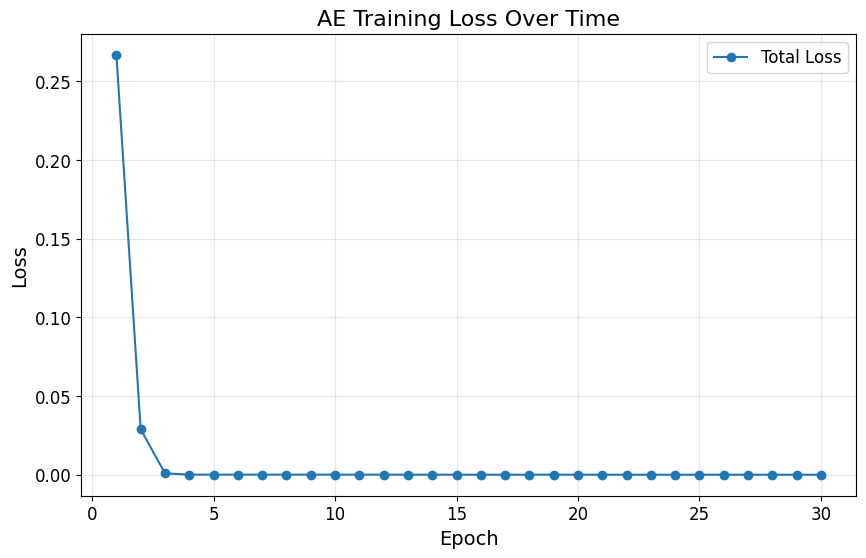

In [4]:

from utils.gating import run_training
ae_model=run_training(nav_signal_tensor=nav_signal_tensor,
                      model_type='ae',
                      learning_rate=0.002,
                      max_epoch=30,
                      hidden_dim1=12,
                      hidden_dim2=8,
                      sampling_rate=(1/TR)        
                      )

### Latent Feature Separation & Theoretical Background

The core objective is to isolate distinct frequency components into individual latent nodes. In this implementation, the separation constraints are explicitly hard-coded; alternatively, soft-penalty loss functions could be employed to learn the latent representations automatically yet not stable.

**Theoretical Context:** Standard Principal Component Analysis (PCA) is mathematically equivalent to a linear autoencoder. Similarly, Independent Component Analysis (ICA) and other blind source separation algorithms operate within the unified framework of non-linear autoencoders configured with specific structural or statistical biases.


Processed nav_signal_tensor shape:  torch.Size([2414, 16])


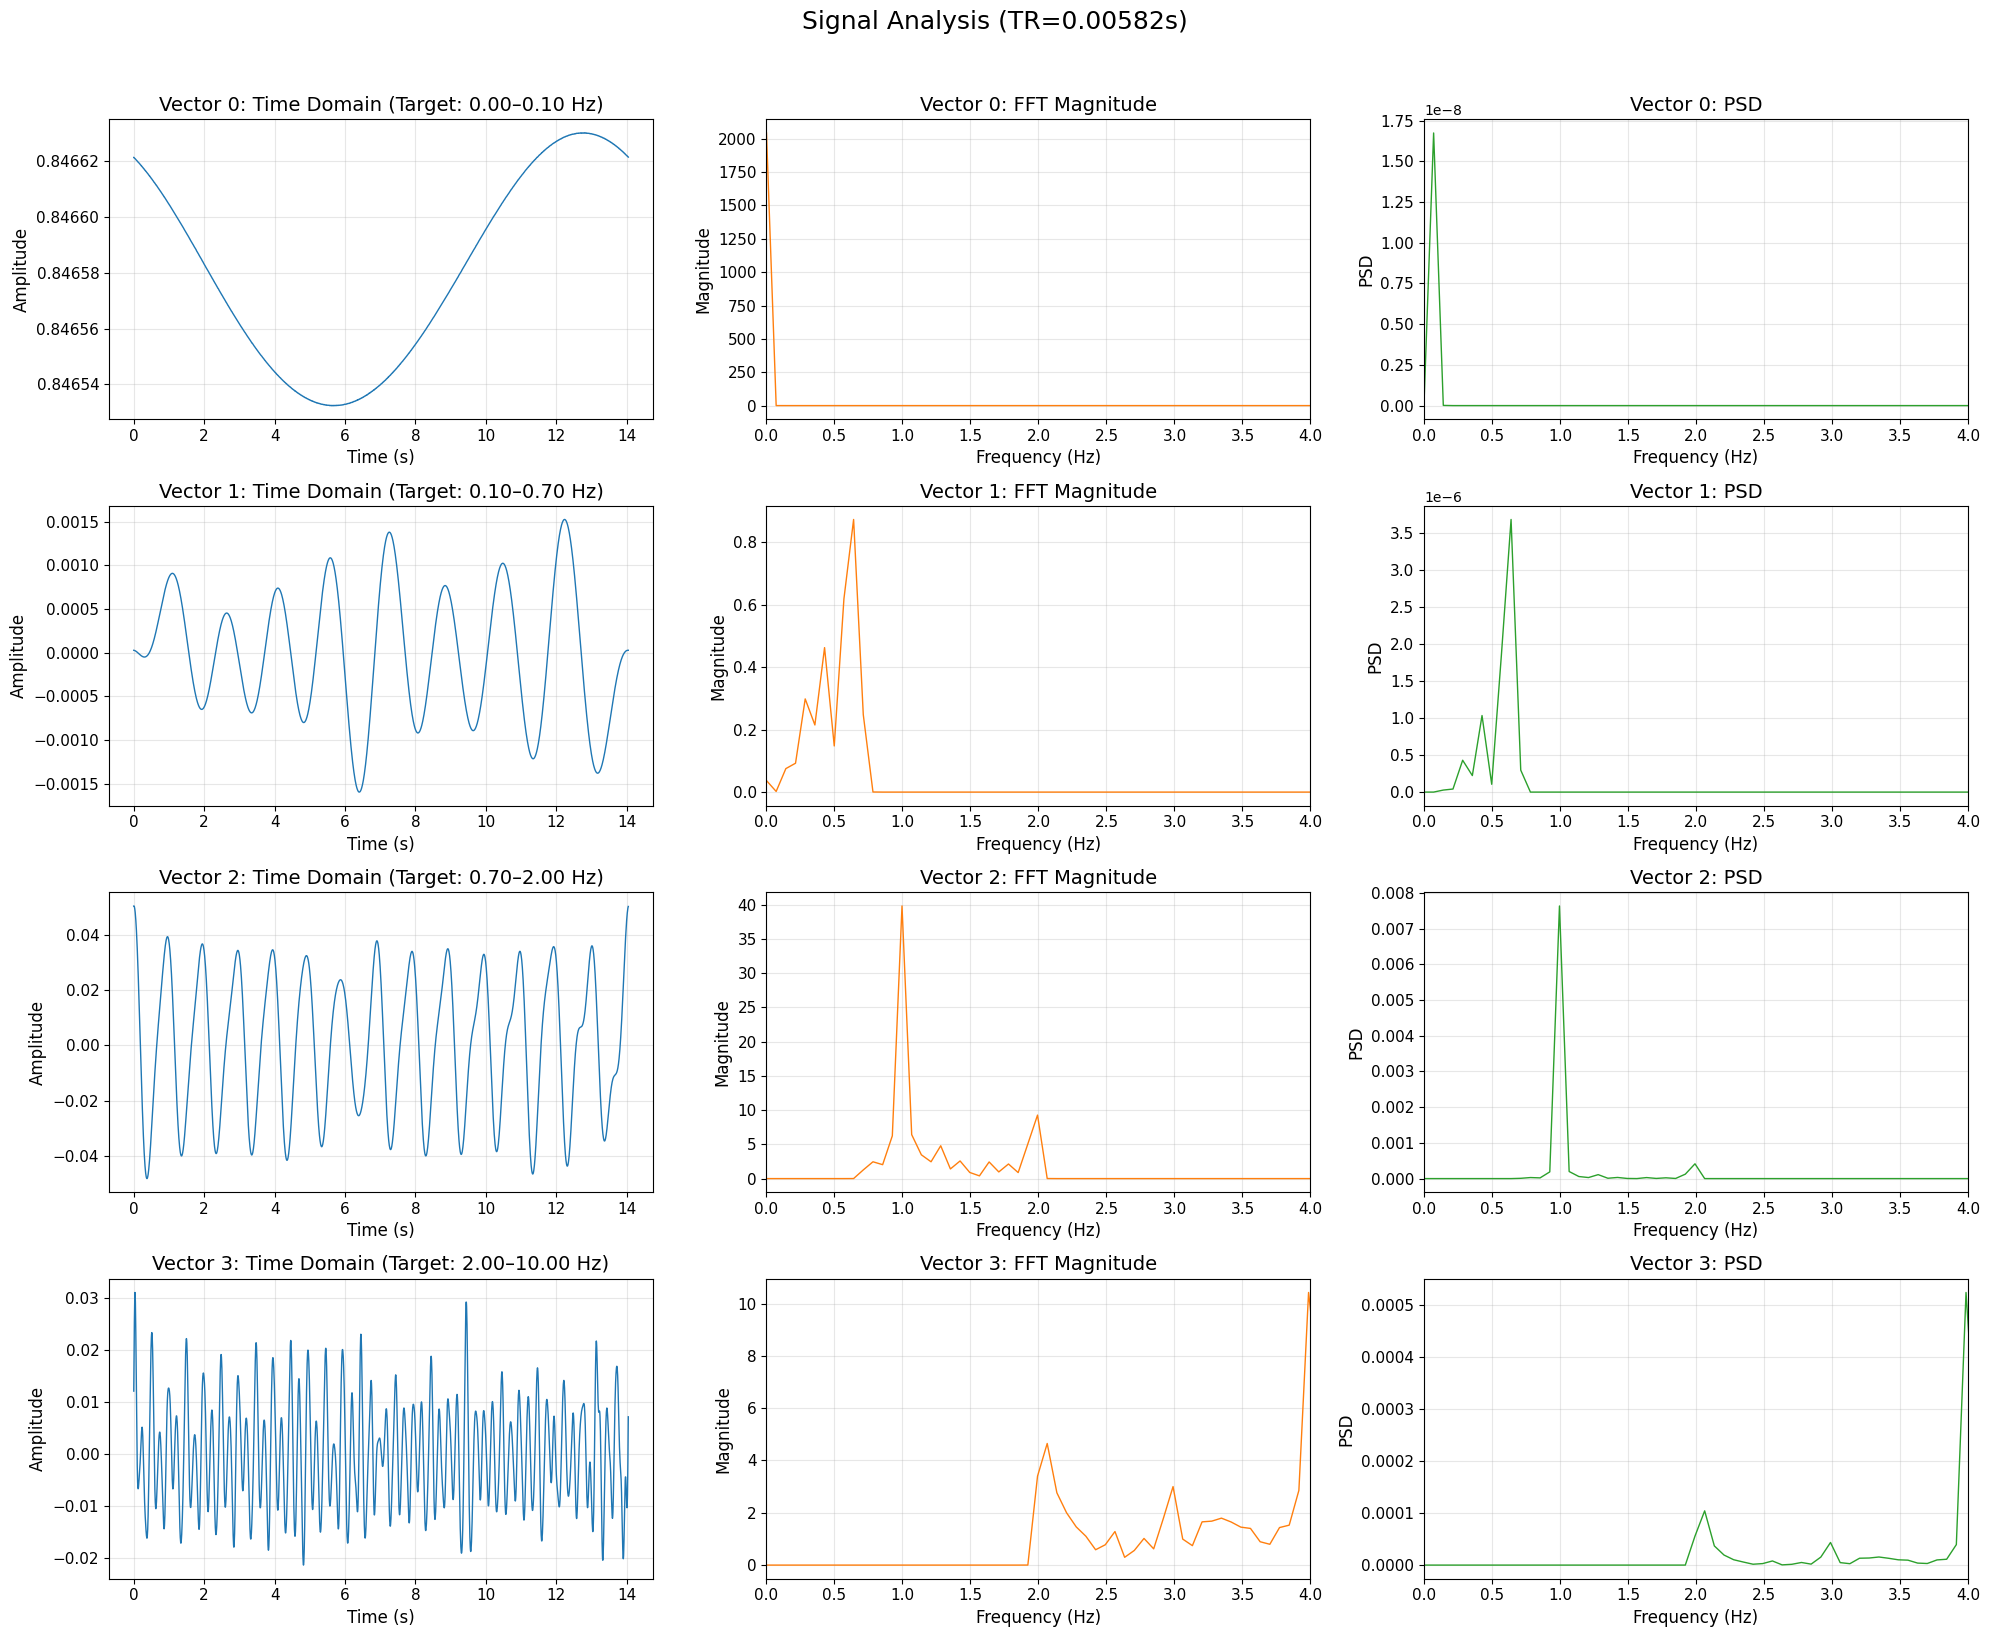

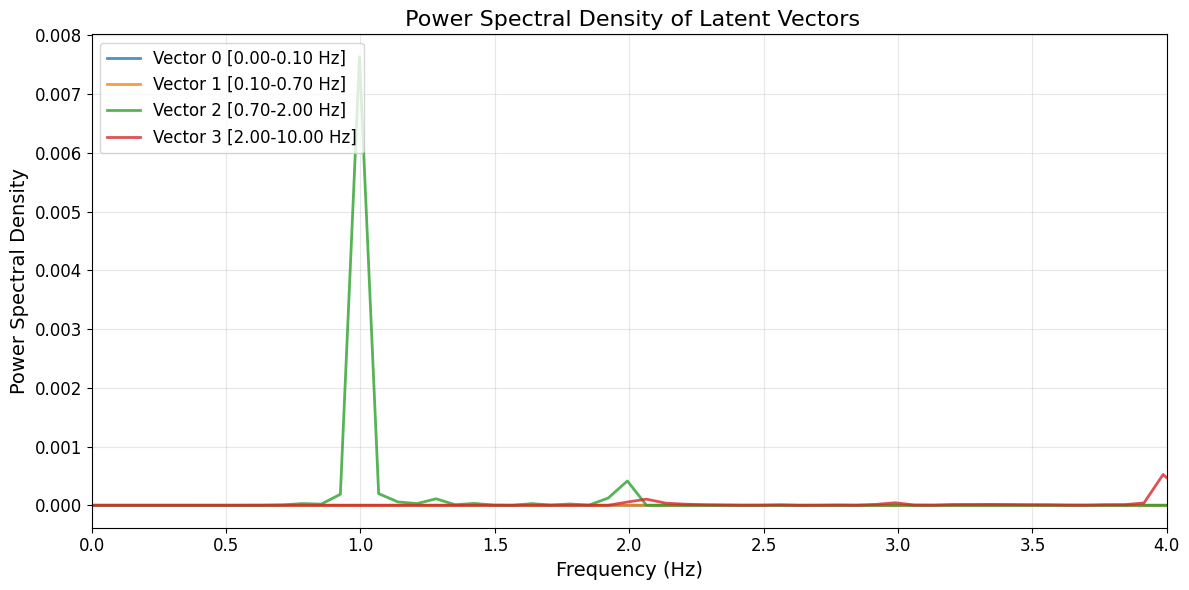


--- Processing Cardiac Signal ---
Peak frequency (Periodogram): 1.00 Hz (from range 0.7-2.0 Hz)
Applied bandpass filter around 1.00 Hz

--- Cardiac Gating Signal Analysis ---
Estimated RR interval from peaks: 1001.4877 ms
Estimated RR interval from valleys: 1010.4415 ms
Estimated heart rate from peaks: 59.9109 BPM
Estimated heart rate from valleys: 59.3800 BPM

Heart Rate Variability (HRV)
RR interval std from peaks: 25.87 ms
RR interval std from valleys: 29.10 ms


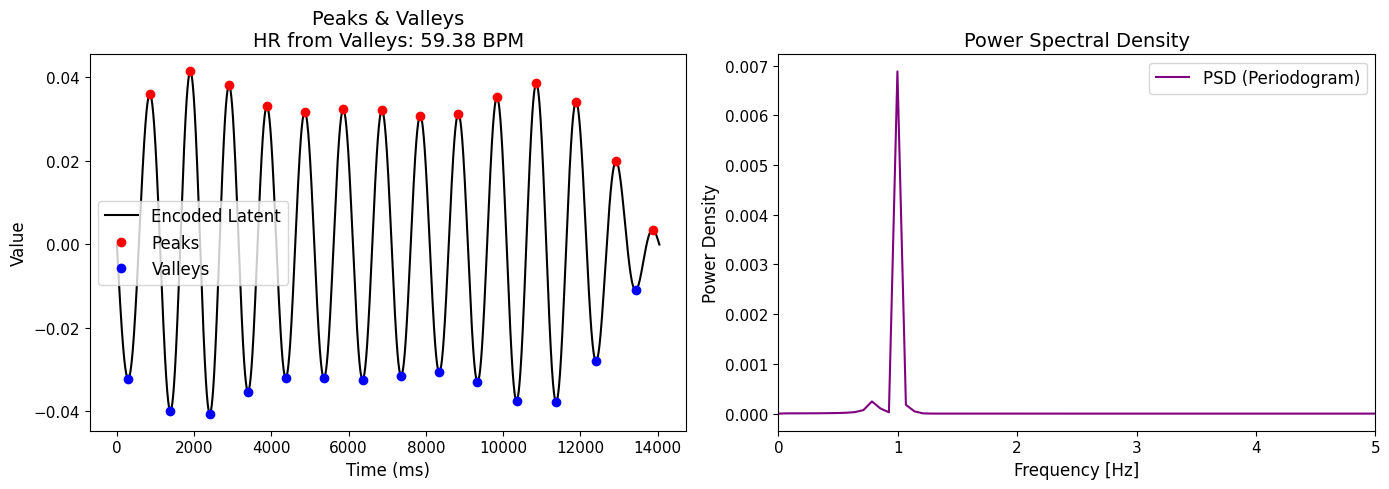

Selected: Peaks (lower variability)


In [5]:
from utils.gating import find_gating_index
cardiac_gating_array, cardiac_peaks, cardiac_valleys = find_gating_index(
    model=ae_model,
    model_type='ae',
    TR=TR,
    nav_signal_tensor=nav_signal_tensor,
    kick_out_num=0,
    plot_all=True,
    order=5,
    bandwidth=0.2,
    include_breath=False
)

## 2. Siemens PMU Data Acquisition

On pre-XA60 Siemens software platforms (we are VE12U), Physiological Measurement Unit (PMU) data is not saved by default unless ECG gating/triggering is active. To overcome this limitation, the sequence was modified as follows:

- **Cardiovascular Cine (CV)**: Operates with default settings, as PMU logging is natively integrated.
- **GRE (`a_gre`) / bSSFP (`trufi`)**: Modified to continuously record PMU data even when active ECG triggering is disabled. (This enables prospective/retrospective gating for applications such as T2* mapping, water-fat separation, 3D imaging, and X-nuclei imaging for our future usage).

### PMU Data Structure & Parsing

1. **PMU Trigger Timestamps**: Recorded vendor trigger events used for gating/triggering (indicated by red dotted lines in plots).
2. **Physiological Signal Channels**: Contains 6 signals — `ECG1`, `ECG2`, `ECG3`, `ECG4`, `EXT1`, and `EXT2` (`EXT1` carries the Acoustic Cardiac Triggering / ACT signal). Raw ECG signals can also be analyzed to assess magnetic field distortion (MHD effect).


Plotting signals and triggers for channels: ECG1, ECG2, ECG3, ECG4, EXT1, EXT2, LEARN_PULS, LEARN_RESP, LEARN_EXT1


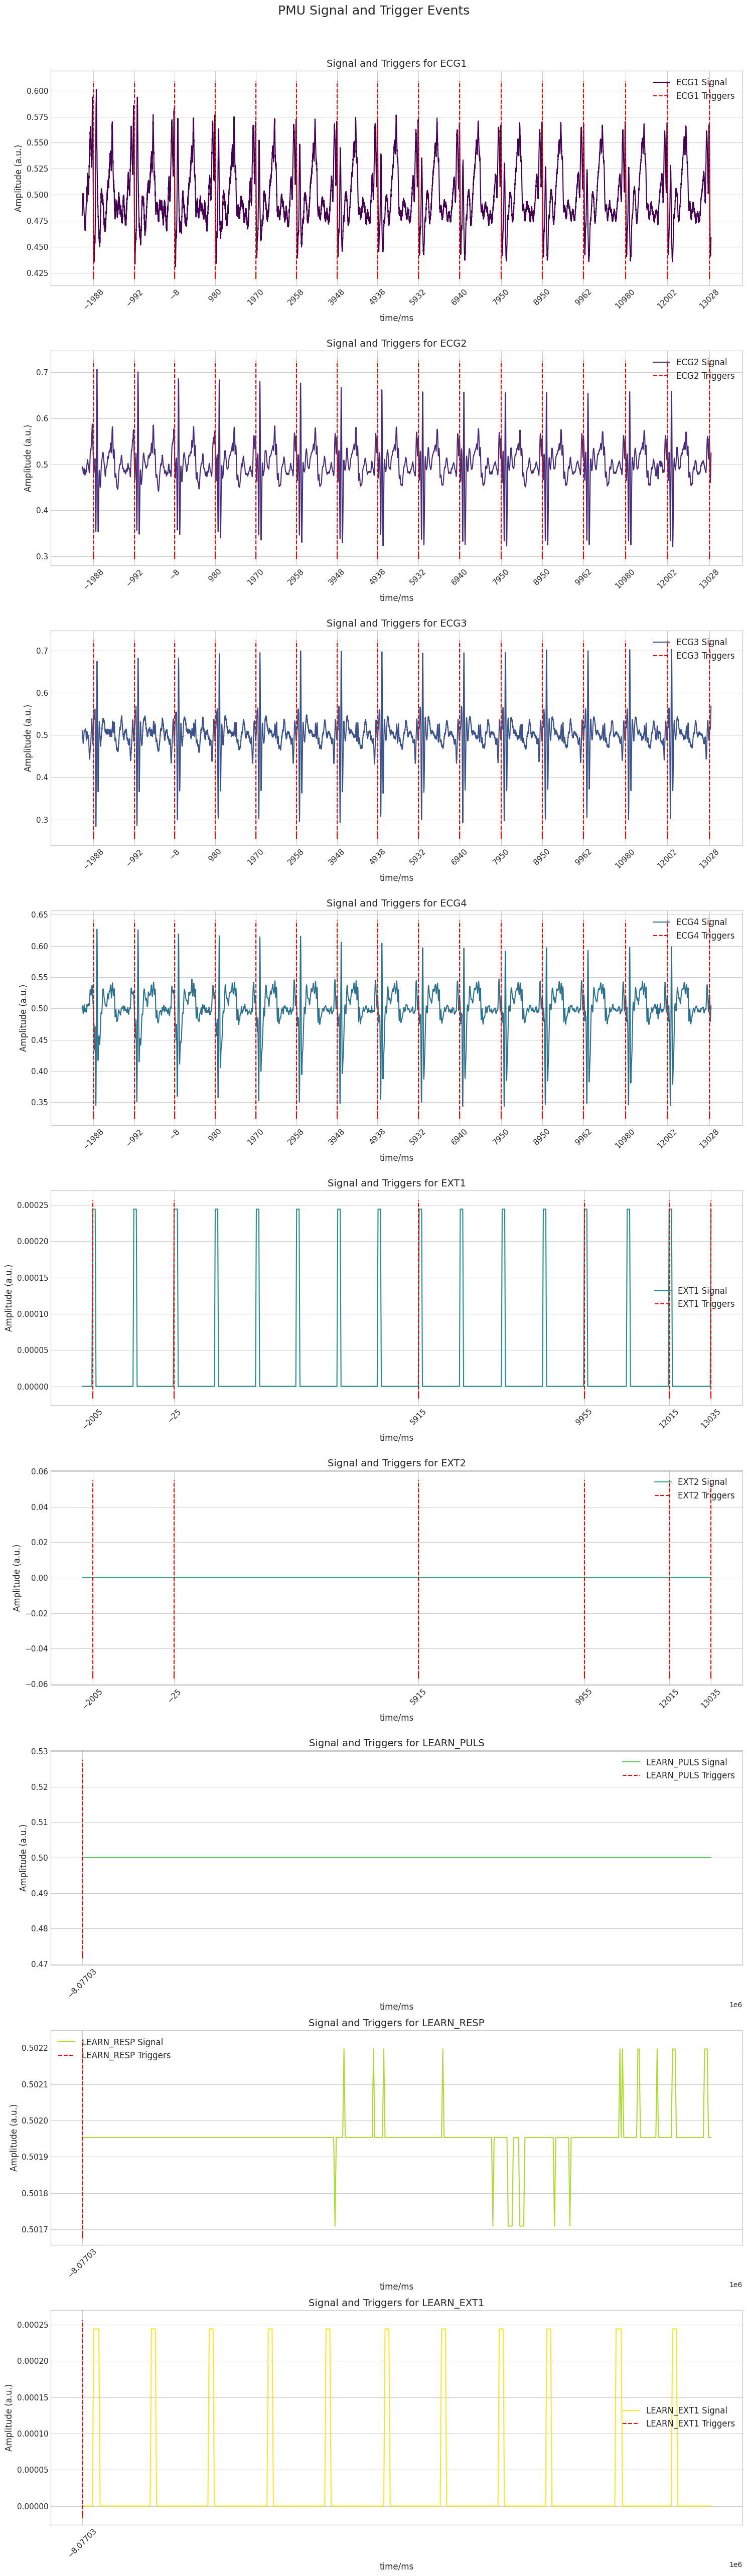

In [6]:
import twixtools as tt
from utils.bin import PMU_Processor
pmu = tt.pmu.PMU(twix[-1]['mdb'])
pmu_processor = PMU_Processor(pmu,beginning_timestamp=beginning_timestamp)
pmu_processor.plot_all_channels()

### PMU & Self-Gating Signal Comparison

Self-gating (SG), ECG, and ACT (TTL pulse) signals can be overlaid for direct comparison, highlighting intrinsic timing offsets between ECG/ACT triggers and self-gating signal peaks.

- **Sampling Frequencies**: Timestamps extracted from TWIX files provide precise timing resolution — 400 Hz for PMU signals and 50 Hz (20 ms resolution) for TTL pulse signals.


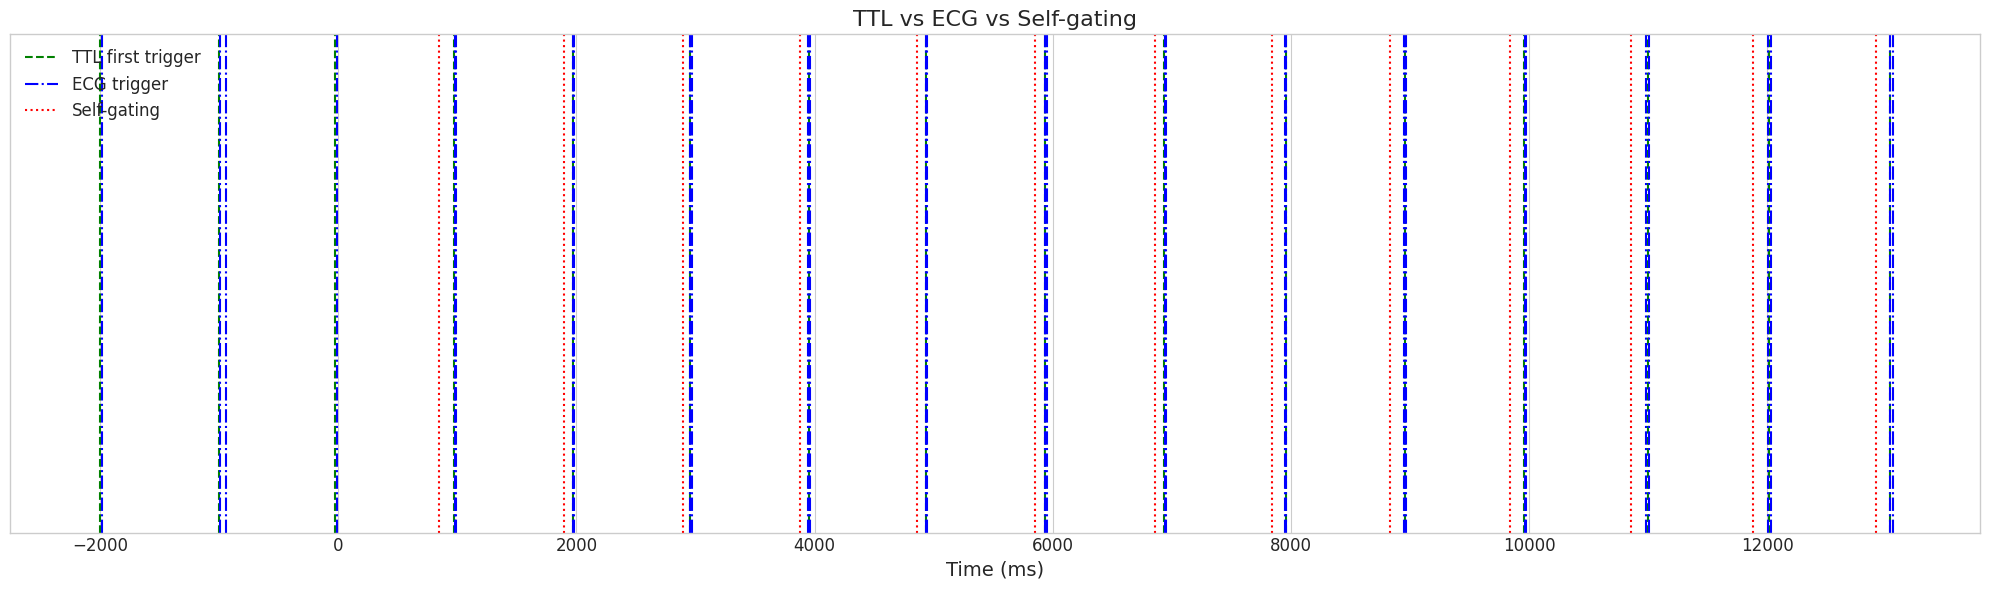

In [7]:
from utils.gating import get_original_indices,find_align_RR_intervals
original_cardiac_gate = get_original_indices(cardiac_gating_array, discard_num, 0)
np.set_printoptions(suppress=True)
origin_trigger_ms=pmu_processor.get_origin_trigger_ms("ECG4")
TTL_first_trigger=pmu_processor.get_TTL_first_trigger()
self_gating_times_ms=original_cardiac_gate[:-1]  * TR * 1000
from utils.gating import calc_metrics,find_align_RR_intervals,plot_gating
plot_gating(self_gating_times_ms,TTL_first_trigger,origin_trigger_ms)

In [8]:
from utils.bin import visualize_k_space_cardiac_phase,fill_kspace_bin,fill_kspace_interpolate
k_space=fill_kspace_interpolate(twix=twix,gating_array=original_cardiac_gate,num_cardiac_phases=30,discard_num=discard_num)


--- Final Hybrid K-Space Interpolation [Discard: 0] ---
Generating Cardiac Map...
Initializing k-space: (16, 576, 248, 1, 30, 1)
Params: Acquired RO=480, Base RO=288, Full Oversampled RO=576, Offset=96
Grouping data for cyclic interpolation...
Final K-Space Shape: (16, 576, 248, 1, 30, 1)


In [9]:

from utils.bin import _to_bart_shape,get_sensitivity,visualize_sens_maps,espirit_recon,show_cine,animate_3d_array,get_noise,noise_to_bart_shape,eliminate_oversampling_gpu
from bart import bart

In [10]:
k_space_bart=_to_bart_shape(k_space)
k_space_cropped=eliminate_oversampling_gpu(k_space_bart)
noise=get_noise(twix)
noise_bart=noise_to_bart_shape(noise)
print("kspace shape for bart:",k_space_bart.shape)
print("noise shape for bart:",noise_bart.shape)
## whitening the coils 
k_space_whiten=bart(1,"whiten",k_space_cropped,noise_bart)

Original shape:    (16, 576, 248, 1, 30, 1)
Expanded shape:    (16, 576, 248, 1, 30, 1, 1, 1, 1, 1, 1, 1)
Final shape:       (576, 248, 1, 16, 1, 1, 1, 1, 1, 1, 30, 1)
(16, 576)
kspace shape for bart: (576, 248, 1, 16, 1, 1, 1, 1, 1, 1, 30, 1)
noise shape for bart: (576, 1, 1, 16, 1, 1, 1, 1, 1, 1, 1, 1)


## 3. Image Reconstruction

By default, GRAPPA acceleration factor 3 with 32 autocalibration signal (ACS) lines is used for reconstruction. Reconstruction parameters can be adjusted with minimal impact on final image quality.


CUDA Pointwise Eigendecomposition...


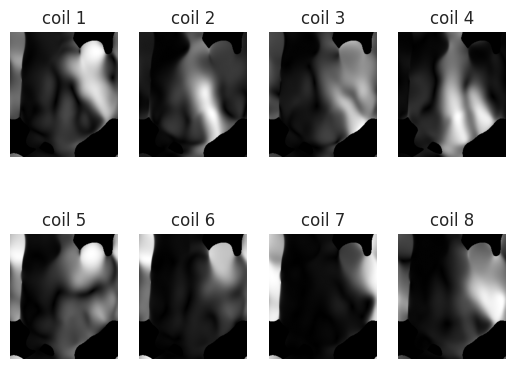

In [11]:
#acs_num
sens_maps=get_sensitivity(k_space_whiten,cal_size=32,kernel_size=6,threshold=1e-4, crop_value=0.15,num_maps=2,use_gpu=True)
visualize_sens_maps(sens_maps,ecalib_ind=0)

In [12]:
l2_reg = 5e-3
recon=bart(1,'pics -R Q:{} -g -S '.format(l2_reg), k_space_cropped, sens_maps)
recon_rss=bart(1,'rss 16', recon)

GPU reconstruction
2 maps.
ESPIRiT reconstruction.
Size: 2142720 Samples: 915840 Acc: 2.34
l2 regularization: 0.005000
Regularization terms: 1, Supporting variables: 0
conjugate gradients
Total Time: 1.602650


In [15]:
animate_3d_array(data=np.abs(recon_rss.squeeze()),interval=100, cmap='gray',save_path=None)
